In [ ]:
import numpy as np
import pandas as pd
print(pd.__version__)
import os

2.2.3


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

base_path = (
    "/content/drive/MyDrive/"
    "Gender classification from tongue images-20261019T043949Z-1-001/"
    "Gender classification from tongue images"
)

print("Path exists:", os.path.isdir(base_path))
print("Folders:", os.listdir(base_path) if os.path.isdir(base_path) else "Path not found")


Path exists: True
Folders: ['Male 311', 'Female 390']


In [ ]:

import pandas as pd

data = []
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

class_folders = {
    "female": os.path.join(base_path, "Female 390"),
    "male": os.path.join(base_path, "Male 311")
}

for label, folder_path in class_folders.items():
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(
            f"Class folder not found: {folder_path}"
        )

    for root, dirs, files in os.walk(folder_path):
        for filename in files:
            if filename.lower().endswith(extensions):
                image_path = os.path.join(root, filename)
                data.append([image_path, label])

df = pd.DataFrame(data, columns=["image_path", "label"])

print("Total images:", len(df))
print(df["label"].value_counts())


Total images: 655
label
female    352
male      303
Name: count, dtype: int64


In [ ]:
df

,image_path,label
0,/content/drive/MyDrive/Gender classification f...,female
1,/content/drive/MyDrive/Gender classification f...,female
2,/content/drive/MyDrive/Gender classification f...,female
3,/content/drive/MyDrive/Gender classification f...,female
4,/content/drive/MyDrive/Gender classification f...,female
...,...,...
650,/content/drive/MyDrive/Gender classification f...,male
651,/content/drive/MyDrive/Gender classification f...,male
652,/content/drive/MyDrive/Gender classification f...,male
653,/content/drive/MyDrive/Gender classification f...,male


In [ ]:
import os

print("Dataset path:", base_path)
print("Path exists:", os.path.exists(base_path))

for item in os.listdir(base_path):
    full_path = os.path.join(base_path, item)

    if os.path.isdir(full_path):
        print(f"\nFolder: {item}")
        print("Number of files:", len(os.listdir(full_path)))
        print("First few files:", os.listdir(full_path)[:5])

Dataset path: /content/drive/MyDrive/Gender classification from tongue images-20261019T043949Z-1-001/Gender classification from tongue images
Path exists: True

Folder: Male 311
Number of files: 310
First few files: ['IMG-20250805-WA0006.jpg', 'IMG-20250807-WA0135 male.jpg', '1000192088.jpg', 'IMG_20250616_144459.jpg', '1000190610.jpg']

Folder: Female 390
Number of files: 353
First few files: ['IMG-20250805-WA0041 female.jpg', '1000188833.jpg', 'WhatsApp Image 2026-09-19 at 12.16.29.jpeg', '1000189163.jpg', '1000190016.jpg']


In [ ]:
import os

for root, dirs, files in os.walk(base_path):
    image_files = [
        f for f in files
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
        )
    ]

    if image_files:
        print("Folder:", root)
        print("Images found:", len(image_files))
        print("Examples:", image_files[:3])

Folder: /content/drive/MyDrive/Gender classification from tongue images-20261019T043949Z-1-001/Gender classification from tongue images/Male 311
Images found: 303
Examples: ['IMG-20250805-WA0006.jpg', 'IMG-20250807-WA0135 male.jpg', '1000192088.jpg']
Folder: /content/drive/MyDrive/Gender classification from tongue images-20261019T043949Z-1-001/Gender classification from tongue images/Female 390
Images found: 352
Examples: ['IMG-20250805-WA0041 female.jpg', '1000188833.jpg', 'WhatsApp Image 2026-09-19 at 12.16.29.jpeg']


In [ ]:
import os

print("Folders inside dataset:")
print(os.listdir(base_path))

Folders inside dataset:
['Male 311', 'Female 390']


In [ ]:
df.shape

(655, 2)

In [ ]:
df.columns

Index(['image_path', 'label'], dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
image_path,0
label,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 655 entries, 0 to 654
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  655 non-null    object
 1   label       655 non-null    object
dtypes: object(2)
memory usage: 10.4+ KB


In [ ]:
df['label'].unique()

array(['female', 'male'], dtype=object)

In [ ]:
df['label'].value_counts()

,count
label,
female,352
male,303


/tmp/ipykernel_5880/22806488.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette="viridis", ax=ax)


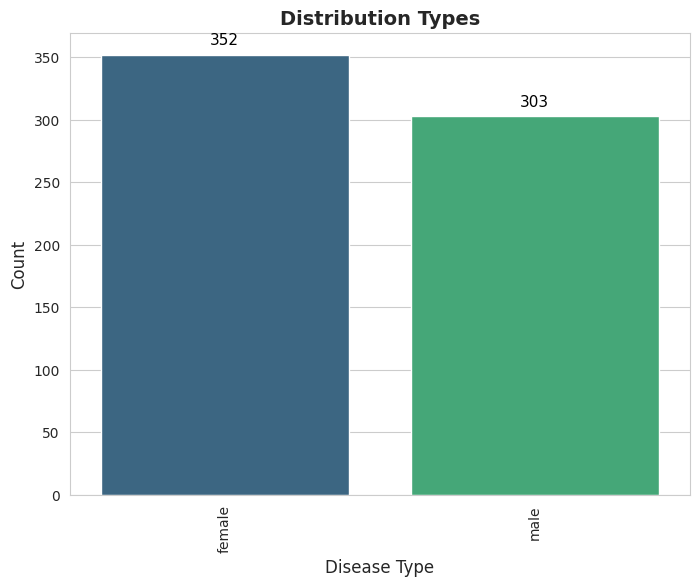

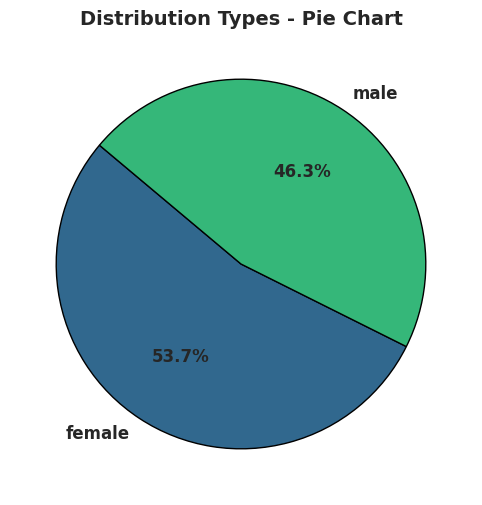

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(data=df, x="label", palette="viridis", ax=ax)

ax.set_title("Distribution Types", fontsize=14, fontweight='bold')
ax.set_xlabel("Disease Type", fontsize=12)
ax.set_ylabel("Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, color='black',
                xytext=(0, 5), textcoords='offset points')

plt.xticks(rotation = 90)
plt.show()

label_counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("viridis", len(label_counts))

ax.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%',
       startangle=140, colors=colors, textprops={'fontsize': 12, 'weight': 'bold'},
       wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax.set_title("Distribution Types - Pie Chart", fontsize=14, fontweight='bold')

plt.show()

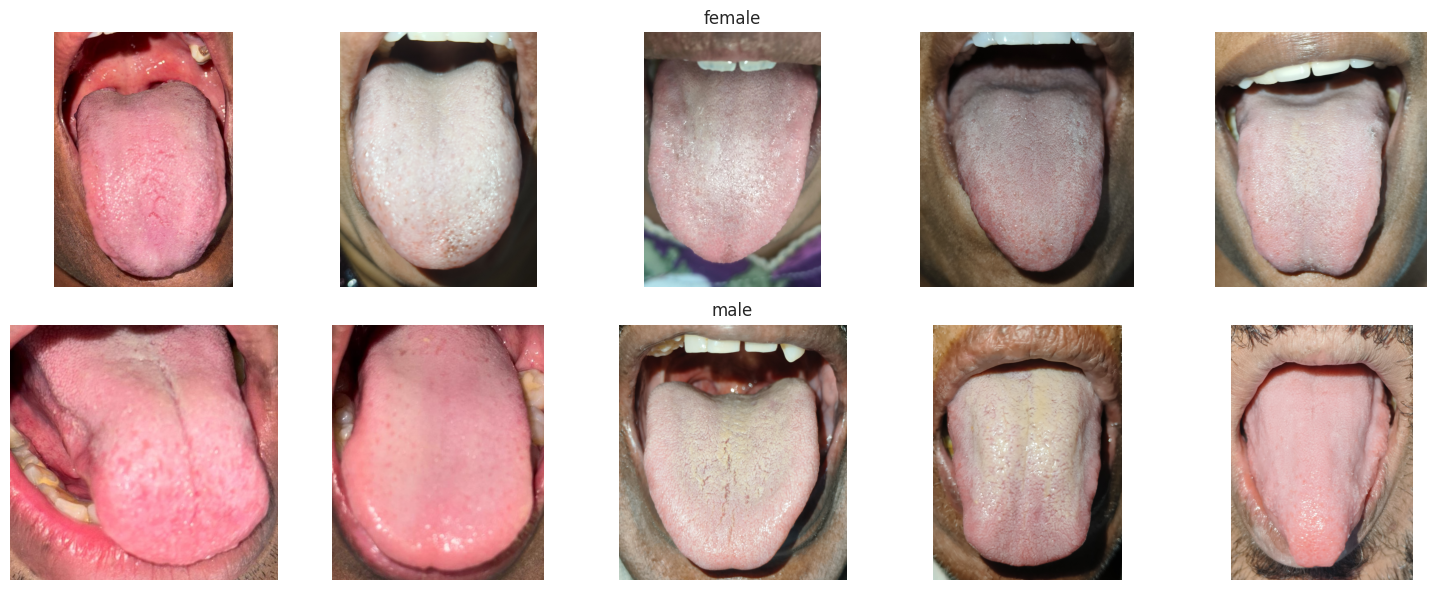

In [ ]:

import cv2
import matplotlib.pyplot as plt

# Select up to 5 images from each class
label_groups = {
    label: group["image_path"].head(5).tolist()
    for label, group in df.groupby("label")
}

num_labels = len(label_groups)

plt.figure(figsize=(15, 3 * num_labels))

for row, (label, images) in enumerate(label_groups.items()):
    for col, img_path in enumerate(images):

        # Read the image
        img = cv2.imread(img_path)

        # Skip unreadable images
        if img is None:
            print("Could not read:", img_path)
            continue

        # Convert BGR to RGB for correct display
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(num_labels, 5, row * 5 + col + 1)
        plt.imshow(img)
        plt.axis("off")

        if col == 2:
            plt.title(label, fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
df


,image_path,label
0,/content/drive/MyDrive/Gender classification f...,female
1,/content/drive/MyDrive/Gender classification f...,female
2,/content/drive/MyDrive/Gender classification f...,female
3,/content/drive/MyDrive/Gender classification f...,female
4,/content/drive/MyDrive/Gender classification f...,female
...,...,...
650,/content/drive/MyDrive/Gender classification f...,male
651,/content/drive/MyDrive/Gender classification f...,male
652,/content/drive/MyDrive/Gender classification f...,male
653,/content/drive/MyDrive/Gender classification f...,male


Usable images by class:\n label
female    352
male      303
Name: count, dtype: int64
Train images: 458 | Validation images: 98 | Test images: 99
Train class counts:
 label
female    246
male      212
Name: count, dtype: int64
Validation class counts:
 label
female    53
male      45
Name: count, dtype: int64
Test class counts:
 label
female    53
male      46
Name: count, dtype: int64
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 102MB/s] 


[Teacher warmup] 1/5  loss=0.5971  acc=0.6638
[Teacher warmup] 2/5  loss=0.4218  acc=0.7969
[Teacher warmup] 3/5  loss=0.3519  acc=0.8341
[Teacher warmup] 4/5  loss=0.2908  acc=0.8821
[Teacher warmup] 5/5  loss=0.2574  acc=0.8996
[Teacher adapt ] 1/5  loss=0.2339  acc=0.9236
[Teacher adapt ] 2/5  loss=0.1713  acc=0.9345
[Teacher adapt ] 3/5  loss=0.1456  acc=0.9367
[Teacher adapt ] 4/5  loss=0.1608  acc=0.9323
[Teacher adapt ] 5/5  loss=0.0897  acc=0.9607
[KD same-view] Epoch 1/20 | train 3.6456/0.5022 | val 3.0394/0.5408
[KD same-view] Epoch 2/20 | train 3.2516/0.5109 | val 2.6977/0.5408
[KD same-view] Epoch 3/20 | train 3.0844/0.5153 | val 2.2421/0.5918
[KD same-view] Epoch 4/20 | train 2.7435/0.5000 | val 2.2774/0.5612
[KD same-view] Epoch 5/20 | train 2.6731/0.5721 | val 2.3040/0.5816
[KD same-view] Epoch 6/20 | train 2.5369/0.5917 | val 2.1072/0.6735
[KD same-view] Epoch 7/20 | train 2.5432/0.5742 | val 2.1528/0.6020
[KD same-view] Epoch 8/20 | train 2.4959/0.6332 | val 1.9612/0.6

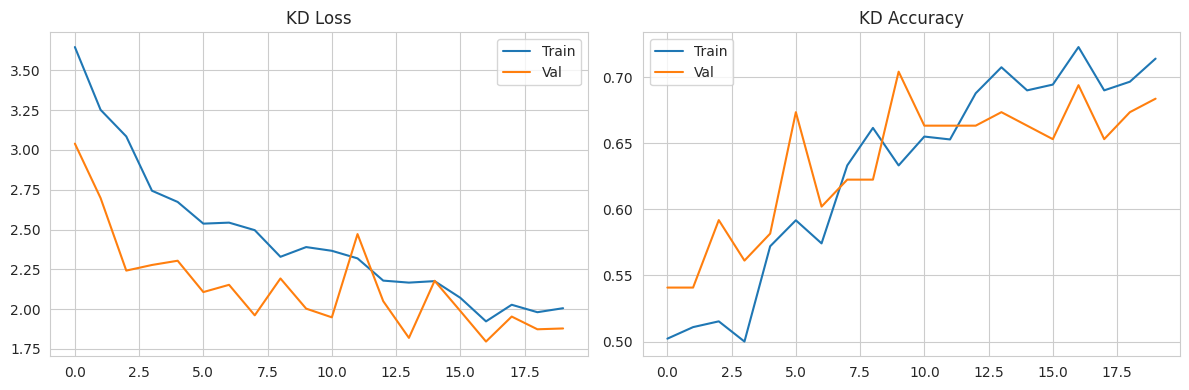

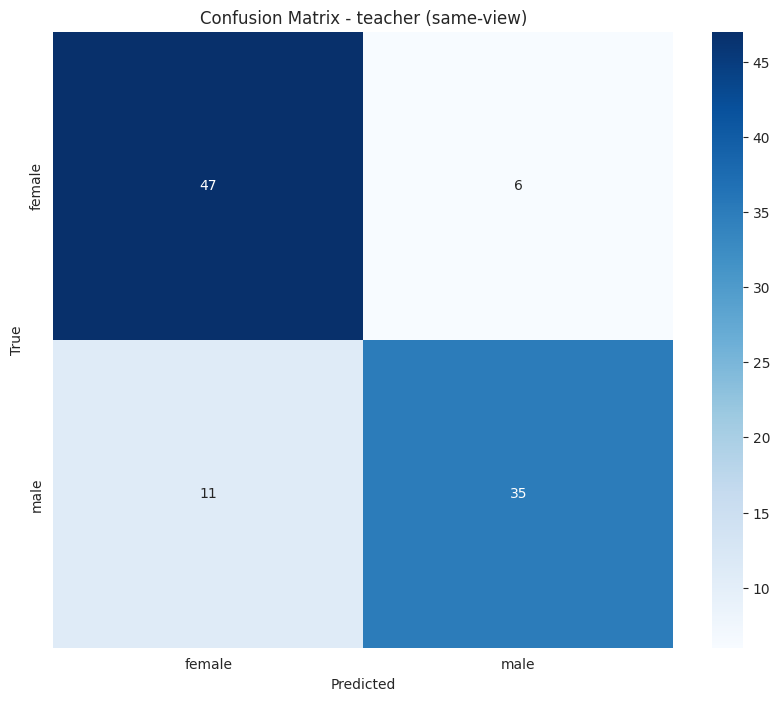

Classification Report - teacher (same-view):
              precision    recall  f1-score   support

      female       0.81      0.89      0.85        53
        male       0.85      0.76      0.80        46

    accuracy                           0.83        99
   macro avg       0.83      0.82      0.83        99
weighted avg       0.83      0.83      0.83        99



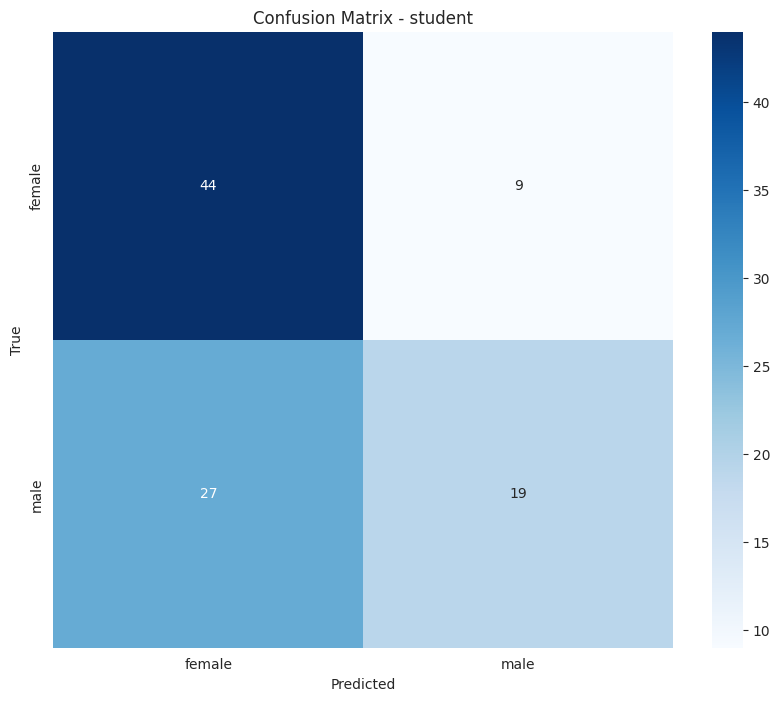

Classification Report - student:
              precision    recall  f1-score   support

      female       0.62      0.83      0.71        53
        male       0.68      0.41      0.51        46

    accuracy                           0.64        99
   macro avg       0.65      0.62      0.61        99
weighted avg       0.65      0.64      0.62        99


Model Parameter Comparison:
Teacher (VGG16): 126,633,474
Student (CNN):   800,706
Compression:     158.15x

Knowledge Retention:
Teacher acc: 0.8283 | Student acc: 0.6364 | Retained: 76.83%


In [ ]:
# =========================
# Binary tongue-image classification: VGG16 teacher → custom CNN student (knowledge distillation)
# =========================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silence TF if present

import json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Repro & device
# -----------------------------
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# EXACT class list (2 classes: binary classification)
# -----------------------------
CLASS_NAMES = ['female', 'male']
num_classes = len(CLASS_NAMES)  # 2
label2id = {c: i for i, c in enumerate(CLASS_NAMES)}
id2label = {i: c for i, c in enumerate(CLASS_NAMES)}

# -----------------------------
# Data prep (expects df with ['image_path','label'])
# -----------------------------
assert 'df' in globals(), "Provide df with columns ['image_path','label']"
assert {'image_path','label'}.issubset(df.columns), "df must have 'image_path' and 'label'"

# (safe) normalize any stray spaces/case in labels
def _norm_label(s):
    label = str(s).strip().lower().replace(' ', '_')
    if label in {'male_82', 'male82'}:
        return 'male'
    return label

df = df.copy()
df['label'] = df['label'].map(_norm_label)

# Drop non-image paths & .ipynb_checkpoints
VALID_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.gif'}
def is_valid_image_path(p):
    p = Path(str(p))
    return p.is_file() and p.suffix.lower() in VALID_EXT and ".ipynb_checkpoints" not in p.parts
df['image_path'] = df['image_path'].astype(str)
df = df[df['image_path'].apply(is_valid_image_path)].reset_index(drop=True)
print('Usable images by class:\\n', df['label'].value_counts())
found_labels = sorted(df['label'].unique())
assert set(found_labels) == set(CLASS_NAMES), f'Expected both classes {CLASS_NAMES}, found {found_labels}'

unknown = set(pd.unique(df['label'])) - set(CLASS_NAMES)
assert not unknown, f"Unknown labels not in CLASS_NAMES: {unknown}"

# Stratified split 70/15/15
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
val_df,   test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])
assert len(train_df) and len(val_df) and len(test_df), 'Train/validation/test split produced an empty set.'

# -----------------------------
# Dataset (student-view only)
# -----------------------------
STUDENT_MEAN = [0.485, 0.456, 0.406]
STUDENT_STD  = [0.229, 0.224, 0.225]
IMG_SIZE = (224, 224)

transform_student_train = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=STUDENT_MEAN, std=STUDENT_STD),
])
transform_student_eval = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=STUDENT_MEAN, std=STUDENT_STD),
])

ImageFile.LOAD_TRUNCATED_IMAGES = True

class CustomImageDataset(Dataset):
    def __init__(self, dataframe, label_map, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.label_map = label_map
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['image_path']).convert('RGB')
        if self.transform is not None:
            img = self.transform(img)
        y = torch.tensor(self.label_map[row['label']], dtype=torch.long)
        return img, y

train_ds = CustomImageDataset(train_df, label2id, transform_student_train)
val_ds   = CustomImageDataset(val_df,   label2id, transform_student_eval)
test_ds  = CustomImageDataset(test_df,  label2id, transform_student_eval)

# Classes are nearly balanced (86 female / 82 male in the current dataset),
# so begin with ordinary shuffled batches instead of oversampling.
nw = 2 if torch.cuda.is_available() else 0
pin = torch.cuda.is_available()
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=nw, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=nw, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=nw, pin_memory=pin)

print(f'Train images: {len(train_ds)} | Validation images: {len(val_ds)} | Test images: {len(test_ds)}')
print('Train class counts:\n', train_df['label'].value_counts())
print('Validation class counts:\n', val_df['label'].value_counts())
print('Test class counts:\n', test_df['label'].value_counts())

# -----------------------------
# Teacher: pretrained VGG16 with a new 2-class classification head
# -----------------------------
teacher = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
in_features = teacher.classifier[6].in_features
teacher.classifier[6] = nn.Linear(in_features, num_classes)
teacher = teacher.to(device)

# ImageNet stats for VGG and student norm tensors
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1,3,1,1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1,3,1,1)
STU_MEAN_T = torch.tensor(STUDENT_MEAN, device=device).view(1,3,1,1)
STU_STD_T  = torch.tensor(STUDENT_STD,  device=device).view(1,3,1,1)

def vgg_logits_from_student(xs, training: bool = False):
    """
    Same-view: student-normalized xs -> denorm -> resize 224 -> VGG norm -> logits.
    training=True keeps autograd for teacher updates; False uses no_grad for speed.
    """
    xs_denorm = xs * STU_STD_T + STU_MEAN_T
    xs_224 = F.interpolate(xs_denorm, size=(224, 224), mode='bilinear', align_corners=False)
    xs_vgg = (xs_224 - IMNET_MEAN) / IMNET_STD
    if training:
        teacher.train()
        return teacher(xs_vgg)                # grad-enabled path
    else:
        teacher.eval()
        with torch.no_grad():
            return teacher(xs_vgg)            # no-grad path

# -----------------------------
# Student: CNN + RoPE + low-rank Gram (lighter)
# -----------------------------
class RotaryPositionEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len=4096):
        super().__init__()
        inv_freq = 1.0 / (10000 ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer("inv_freq", inv_freq)
        self.max_seq_len = max_seq_len
        t = torch.arange(self.max_seq_len)
        freqs = torch.einsum("i,j->ij", t, inv_freq)
        emb = torch.cat((freqs.cos(), freqs.sin()), dim=-1).float()
        self.register_buffer("cos_cached", emb[None, :, :])
        self.register_buffer("sin_cached", emb[None, :, :])
    def forward(self, x):  # [B,P,D]
        P = min(x.shape[1], self.max_seq_len)
        cos = self.cos_cached[:, :P, :].to(x.device)
        sin = self.sin_cached[:, :P, :].to(x.device)
        x = x[:, :P, :]
        return x * cos + torch.flip(x, dims=[-1]) * sin

class GramAnchoring(nn.Module):
    def __init__(self, embed_dim, reduced_dim=32):
        super().__init__()
        self.proj = nn.Linear(embed_dim, reduced_dim, bias=False)
    def forward(self, feats, teacher_feats=None):  # [B,P,D]
        if teacher_feats is None:
            teacher_feats = feats.detach()
        s = F.normalize(self.proj(feats), p=2, dim=-1)  # [B,P,d]
        t = F.normalize(self.proj(teacher_feats), p=2, dim=-1)
        gram_s = torch.bmm(s.transpose(1, 2), s)        # [B,d,d]
        gram_t = torch.bmm(t.transpose(1, 2), t)
        return gram_s, gram_t

class StudentCNN(nn.Module):
    def __init__(self, num_classes=num_classes, in_ch=3, embed_dim=64, token_side=128, gram_red=32):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, 64, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(64)
        self.conv2 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn2   = nn.BatchNorm2d(128)
        self.conv3 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn3   = nn.BatchNorm2d(256)
        self.conv4 = nn.Conv2d(256, embed_dim, 3, padding=1)  # projects 256 -> embed_dim
        self.bn4   = nn.BatchNorm2d(embed_dim)
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool2d(2, 2)

        with torch.no_grad():
            d = torch.zeros(1, in_ch, token_side, token_side)
            x = self.pool(self.relu(self.conv1(d)))
            x = self.pool(self.relu(self.conv2(x)))
            x = self.pool(self.relu(self.conv3(x)))
            x = self.relu(self.conv4(x))   # NOTE: no extra pool here, keep spatial size consistent with forward()
            patches = x.shape[2] * x.shape[3]

        self.rope = RotaryPositionEmbedding(embed_dim, max_seq_len=patches)
        self.gram = GramAnchoring(embed_dim, reduced_dim=gram_red)
        gram_size = gram_red * gram_red
        self.fc1  = nn.Linear(embed_dim + gram_size, 256)
        self.drop = nn.Dropout(0.5)
        self.fc2  = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.relu(self.conv4(x))       # NEW: project 256 -> embed_dim (64), matches __init__ probe
        B, D, H, W = x.shape                # D == embed_dim now
        tokens = x.permute(0,2,3,1).contiguous().view(B, H*W, D)  # [B,P,D]
        tokens = self.rope(tokens)
        gram_s, _ = self.gram(tokens)
        pooled = tokens.mean(dim=1)
        combined = torch.cat([pooled, gram_s.view(B, -1)], dim=1)
        h = self.drop(F.relu(self.fc1(combined)))
        return self.fc2(h)

student = StudentCNN(num_classes=num_classes, in_ch=3, embed_dim=64, token_side=224, gram_red=32).to(device)

# -----------------------------
# Loss (KD) and helpers
# -----------------------------
def kd_loss(student_logits, teacher_logits, labels, temperature=3.0, alpha=0.5,
            class_weights=None, label_smoothing=0.05):
    T = temperature
    with torch.no_grad():
        soft_t = F.softmax(teacher_logits / T, dim=-1)
    loss_kd = F.kl_div(F.log_softmax(student_logits / T, dim=-1),
                       soft_t, reduction='batchmean') * (T * T)
    loss_ce = F.cross_entropy(student_logits, labels,
                              weight=class_weights, label_smoothing=label_smoothing)
    return alpha * loss_ce + (1.0 - alpha) * loss_kd

def count_parameters(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# The two classes are close to balanced, so use equal class weighting initially.
class_weights_t = None

# -----------------------------
# Teacher warm-up (head-only) → partial unfreeze (VGG)
# -----------------------------
# Freeze conv backbone first; train only classifier head
for p in teacher.features.parameters():
    p.requires_grad = False
for p in teacher.classifier.parameters():
    p.requires_grad = True

teacher_opt = optim.AdamW(filter(lambda p: p.requires_grad, teacher.parameters()), lr=1e-4, weight_decay=1e-4)
ce = nn.CrossEntropyLoss()

def train_teacher_epoch():
    teacher.train()
    tot, corr, n = 0.0, 0, 0
    for xs, ys in train_loader:
        xs, ys = xs.to(device), ys.to(device)
        teacher_opt.zero_grad(set_to_none=True)
        logits = vgg_logits_from_student(xs, training=True)  # grad-enabled
        loss = ce(logits, ys)
        loss.backward()
        teacher_opt.step()
        tot += loss.item() * xs.size(0)
        corr += (logits.argmax(1) == ys).sum().item()
        n += xs.size(0)
    return tot/n, corr/n

# Warm-up classifier
E_WARM = 5
for ep in range(E_WARM):
    tl, ta = train_teacher_epoch()
    print(f"[Teacher warmup] {ep+1}/{E_WARM}  loss={tl:.4f}  acc={ta:.4f}")

# Partial unfreeze: last conv block (features[24:]) + classifier
for p in teacher.parameters(): p.requires_grad = False
for p in teacher.features[24:].parameters(): p.requires_grad = True  # VGG16 last conv block
for p in teacher.classifier.parameters():     p.requires_grad = True

teacher_opt = optim.AdamW(filter(lambda p: p.requires_grad, teacher.parameters()), lr=5e-5, weight_decay=1e-4)
E_ADAPT = 5
for ep in range(E_ADAPT):
    tl, ta = train_teacher_epoch()
    print(f"[Teacher adapt ] {ep+1}/{E_ADAPT}  loss={tl:.4f}  acc={ta:.4f}")

teacher.eval()

# -----------------------------
# Student optimizer: cosine LR with warmup + grad clipping
# -----------------------------
student_opt = optim.AdamW(student.parameters(), lr=3e-4, weight_decay=1e-4)

def cosine_warmup_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * float(step) / float(max(1, warmup_steps))
    progress = float(step - warmup_steps) / float(max(1, total_steps - warmup_steps))
    return base_lr * 0.5 * (1.0 + np.cos(np.pi * progress))

EPOCHS_KD = 20
steps_per_epoch = len(train_loader)
total_steps = EPOCHS_KD * steps_per_epoch
warmup_steps = int(0.1 * total_steps)
base_lr = 3e-4

# -----------------------------
# KD Training (same-view) — uses a single history dict
# -----------------------------
def train_kd_PVAnamoly_VGG16_sameview1():
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    global_step = 0
    for ep in range(EPOCHS_KD):
        # Train
        student.train()
        tl_sum, correct, n = 0.0, 0, 0
        for xs, ys in train_loader:
            xs, ys = xs.to(device), ys.to(device)

            # update LR
            lr = cosine_warmup_lr(global_step, total_steps, warmup_steps, base_lr)
            for g in student_opt.param_groups: g['lr'] = lr
            global_step += 1

            student_opt.zero_grad(set_to_none=True)
            s_logits = student(xs)
            t_logits = vgg_logits_from_student(xs, training=False)  # SAME VIEW (no grad)
            loss = kd_loss(s_logits, t_logits, ys, temperature=3.0, alpha=0.3,
                           class_weights=class_weights_t, label_smoothing=0.05)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            student_opt.step()

            tl_sum += loss.item() * xs.size(0)
            correct += (s_logits.argmax(1) == ys).sum().item()
            n += xs.size(0)
        tr_loss, tr_acc = tl_sum/n, correct/n

        # Validate
        student.eval()
        vl_sum, vcorrect, vn = 0.0, 0, 0
        with torch.no_grad():
            for xs, ys in val_loader:
                xs, ys = xs.to(device), ys.to(device)
                s_logits = student(xs)
                t_logits = vgg_logits_from_student(xs, training=False)
                loss = kd_loss(s_logits, t_logits, ys, temperature=3.0, alpha=0.3,
                               class_weights=class_weights_t, label_smoothing=0.05)
                vl_sum += loss.item() * xs.size(0)
                vcorrect += (s_logits.argmax(1) == ys).sum().item()
                vn += xs.size(0)
        va_loss, va_acc = vl_sum/vn, vcorrect/vn

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        print(f"[KD same-view] Epoch {ep+1}/{EPOCHS_KD} | train {tr_loss:.4f}/{tr_acc:.4f} | val {va_loss:.4f}/{va_acc:.4f}")
    return history

history = train_kd_PVAnamoly_VGG16_sameview1()

# -----------------------------
# Plots
# -----------------------------
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history['train_loss'], label='Train'); plt.plot(history['val_loss'], label='Val')
plt.title('KD Loss'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history['train_acc'], label='Train'); plt.plot(history['val_acc'], label='Val')
plt.title('KD Accuracy'); plt.legend()
plt.tight_layout(); plt.show()

# -----------------------------
# Evaluation (teacher same-view & student)
# -----------------------------
def evaluate_student(model, loader, class_names, title='student'):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xs, ys in loader:
            xs, ys = xs.to(device), ys.to(device)
            logits = model(xs)
            preds.extend(logits.argmax(1).cpu().tolist())
            labels.extend(ys.cpu().tolist())
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))))
    plt.figure(figsize=(max(10,len(class_names)), max(8,len(class_names))))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {title}'); plt.ylabel('True'); plt.xlabel('Predicted'); plt.show()
    print(f'Classification Report - {title}:')
    print(classification_report(labels, preds, target_names=class_names, zero_division=0))
    return classification_report(labels, preds, target_names=class_names, zero_division=0, output_dict=True)

def evaluate_teacher_sameview(loader, class_names, title='teacher (same-view)'):
    teacher.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xs, ys in loader:
            xs, ys = xs.to(device), ys.to(device)
            logits = vgg_logits_from_student(xs, training=False)
            preds.extend(logits.argmax(1).cpu().tolist())
            labels.extend(ys.cpu().tolist())
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))))
    plt.figure(figsize=(max(10,len(class_names)), max(8,len(class_names))))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {title}'); plt.ylabel('True'); plt.xlabel('Predicted'); plt.show()
    print(f'Classification Report - {title}:')
    print(classification_report(labels, preds, target_names=class_names, zero_division=0))
    return classification_report(labels, preds, target_names=class_names, zero_division=0, output_dict=True)

teacher_report = evaluate_teacher_sameview(test_loader, CLASS_NAMES, 'teacher (same-view)')
student_report = evaluate_student(student, test_loader, CLASS_NAMES, 'student')

print("\nModel Parameter Comparison:")
print(f"Teacher (VGG16): {count_parameters(teacher):,}")
print(f"Student (CNN):   {count_parameters(student):,}")
print(f"Compression:     {count_parameters(teacher)/max(1,count_parameters(student)):.2f}x")
print("\nKnowledge Retention:")
print(f"Teacher acc: {teacher_report['accuracy']:.4f} | Student acc: {student_report['accuracy']:.4f} | "
      f"Retained: {(student_report['accuracy']/max(teacher_report['accuracy'],1e-9)*100):.2f}%")

In [ ]:

# ==========================================
# EXPORT: Checkpoint (.pth) + Android (.ptl)
# ==========================================

from pathlib import Path
from copy import deepcopy
import torch
import torch.nn.functional as F
from torch.utils.mobile_optimizer import optimize_for_mobile
import cv2

EXPORT_DIR = Path("export")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Metadata
ARTIFACTS = {
    "labels": CLASS_NAMES,
    "mean": STUDENT_MEAN,
    "std": STUDENT_STD,
    "img_size": list(IMG_SIZE),
    "arch": "StudentCNN",
}

# A. Save trained model checkpoint
torch.save({
    "state_dict": {
        k: v.detach().cpu()
        for k, v in student.state_dict().items()
    },
    "meta": ARTIFACTS,
    "arch": "StudentCNN",
}, EXPORT_DIR / "student_fp32.pth")

# B. Export a CPU copy; keep original student unchanged
student_cpu = deepcopy(student).eval().cpu()

# IMPORTANT:
# In your model definition, change F.normalize(..., p=2, ...)
# to F.normalize(..., p=2.0, ...) before scripting.
example = torch.randn(1, 3, *IMG_SIZE)

try:
    ts = torch.jit.script(student_cpu)
    print("TorchScript scripting successful.")

except Exception as e:
    print("Scripting failed; falling back to tracing:", e)
    ts = torch.jit.trace(student_cpu, example)

# Optimize and save mobile model
ts_mobile = optimize_for_mobile(ts)

ts_mobile._save_for_lite_interpreter(
    str(EXPORT_DIR / "student_mobile.ptl")
)

# C. Verify files
for filename in ["student_fp32.pth", "student_mobile.ptl"]:
    path = EXPORT_DIR / filename
    print(
        f"{filename}:",
        "Saved successfully" if path.exists() else "MISSING",
        f"| Size: {path.stat().st_size / (1024 * 1024):.2f} MB"
        if path.exists() else ""
    )


Scripting failed; falling back to tracing: 

normalize(Tensor input, float p=2., int dim=1, float eps=9.9999999999999998e-13, Tensor? out=None) -> Tensor:
Expected a value of type 'float' for argument 'p' but instead found type 'int'.
:
  File "/tmp/ipykernel_5880/3667473235.py", line 187
        if teacher_feats is None:
            teacher_feats = feats.detach()
        s = F.normalize(self.proj(feats), p=2, dim=-1)  # [B,P,d]
            ~~~~~~~~~~~ <--- HERE
        t = F.normalize(self.proj(teacher_feats), p=2, dim=-1)
        gram_s = torch.bmm(s.transpose(1, 2), s)        # [B,d,d]



/tmp/ipykernel_5880/3667473235.py:174: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  P = min(x.shape[1], self.max_seq_len)


student_fp32.pth: Saved successfully | Size: 3.45 MB
student_mobile.ptl: Saved successfully | Size: 3.25 MB


/tmp/ipykernel_5880/2674380789.py:53: DeprecationWarning: Lite Interpreter is deprecated. Please consider switching to ExecuTorch.             https://docs.pytorch.org/executorch/stable/getting-started.html
  ts_mobile._save_for_lite_interpreter(


In [ ]:
import torch
from pathlib import Path

mobile_path = Path("export/student_mobile.ptl")

if mobile_path.exists():
    mobile_model = torch.jit.load(str(mobile_path), map_location="cpu")
    mobile_model.eval()

    example = torch.randn(1, 3, *IMG_SIZE)

    with torch.no_grad():
        output = mobile_model(example)

    print("Mobile model loaded successfully.")
    print("Output shape:", output.shape)
    print("Output:", output)
else:
    print("Mobile model file not found.")

Mobile model loaded successfully.
Output shape: torch.Size([1, 2])
Output: tensor([[-2.3520,  9.7256]])


In [ ]:
import torch

with torch.no_grad():
    output = mobile_model(example)

probabilities = torch.softmax(output, dim=1)
predicted_index = output.argmax(dim=1).item()
predicted_class = CLASS_NAMES[predicted_index]

print("Predicted class:", predicted_class)
print("Probabilities:", probabilities[0].tolist())

Predicted class: male
Probabilities: [5.685340511263348e-06, 0.9999942779541016]


In [ ]:
# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

teacher = teacher.to(device).eval()
student = student.to(device).eval()

print("Using device:", device)
print("Teacher device:", next(teacher.parameters()).device)
print("Student device:", next(student.parameters()).device)

Using device: cuda
Teacher device: cuda:0
Student device: cuda:0


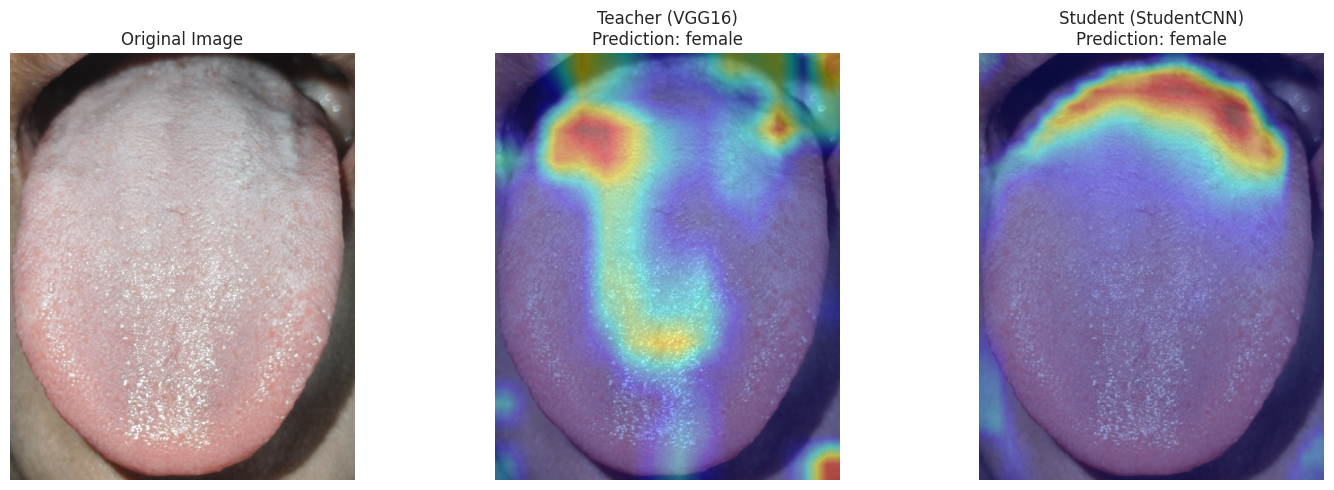

Saved: export/gradcam/gradcam_comparison_1.png
Teacher prediction: female
Student prediction: female
--------------------------------------------------


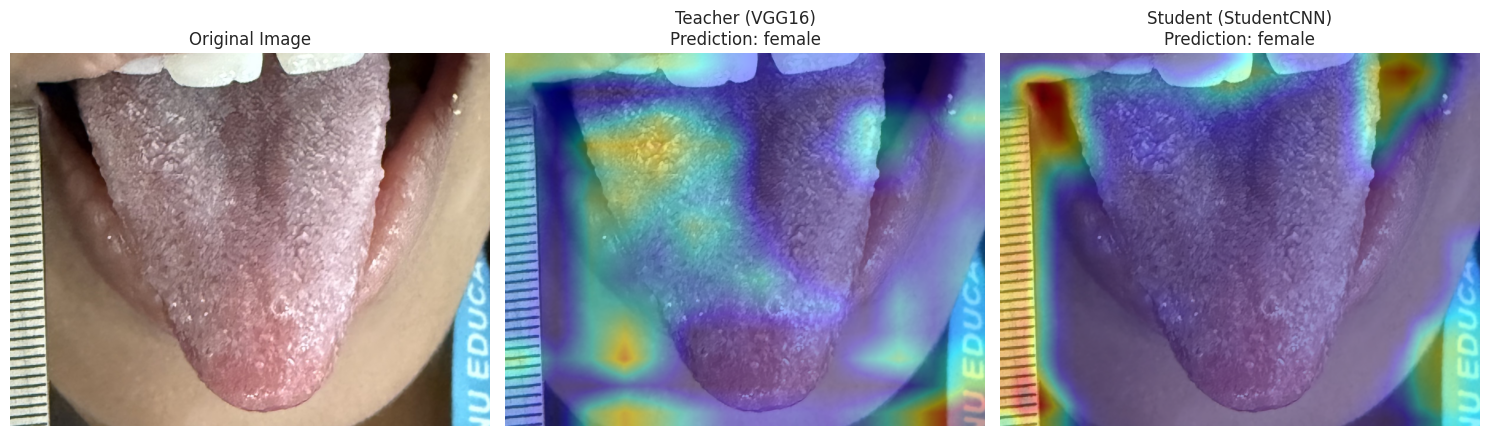

Saved: export/gradcam/gradcam_comparison_2.png
Teacher prediction: female
Student prediction: female
--------------------------------------------------


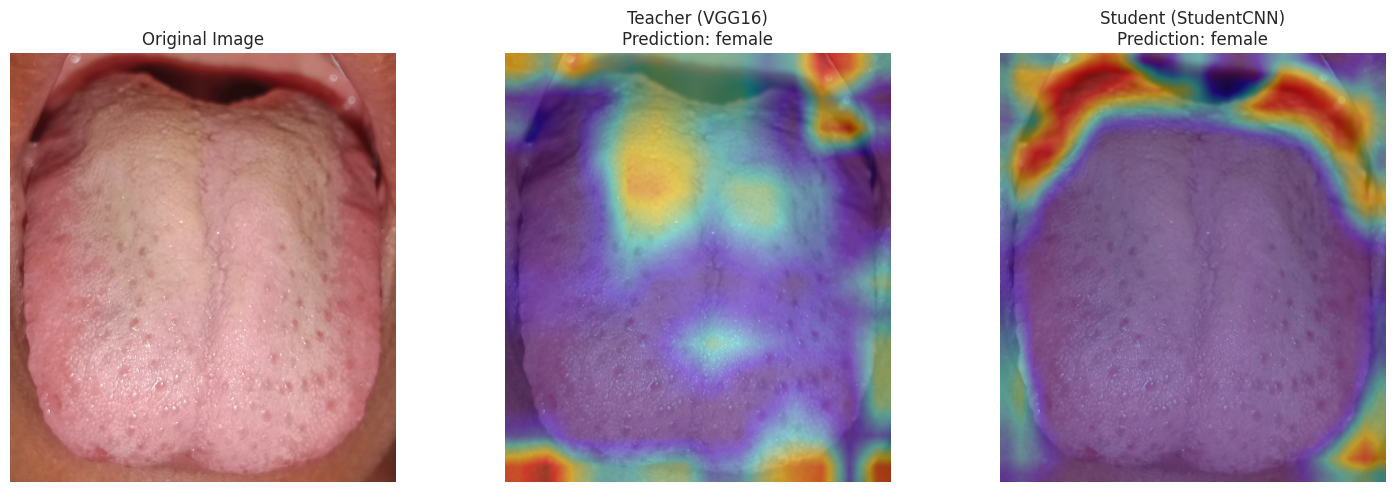

Saved: export/gradcam/gradcam_comparison_3.png
Teacher prediction: female
Student prediction: female
--------------------------------------------------


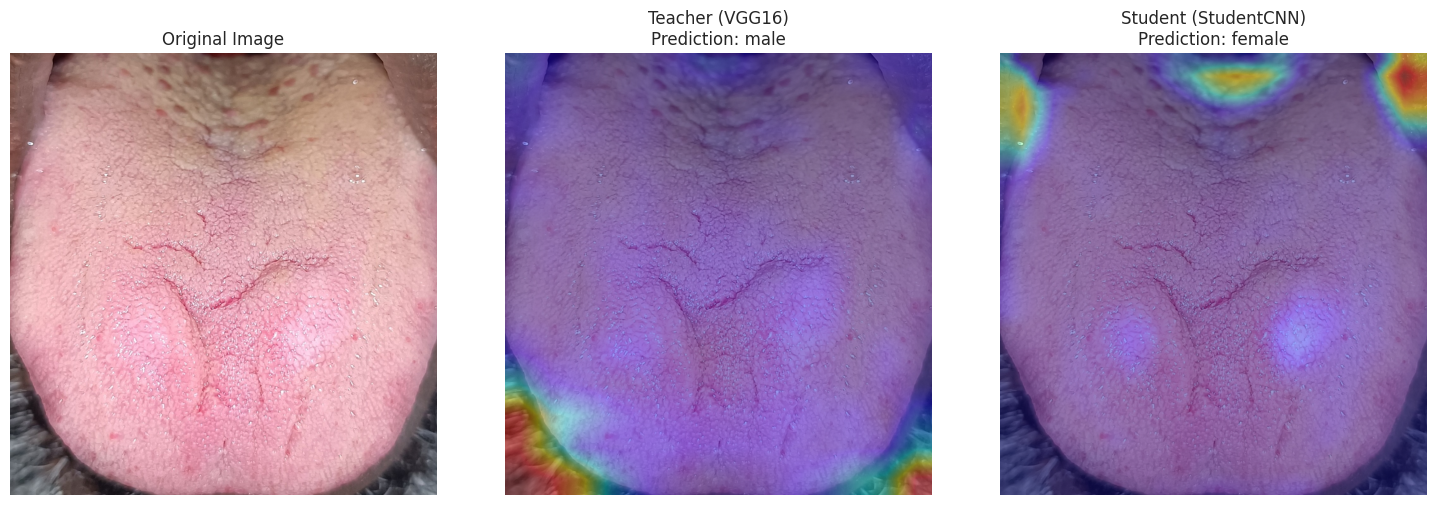

Saved: export/gradcam/gradcam_comparison_4.png
Teacher prediction: male
Student prediction: female
--------------------------------------------------


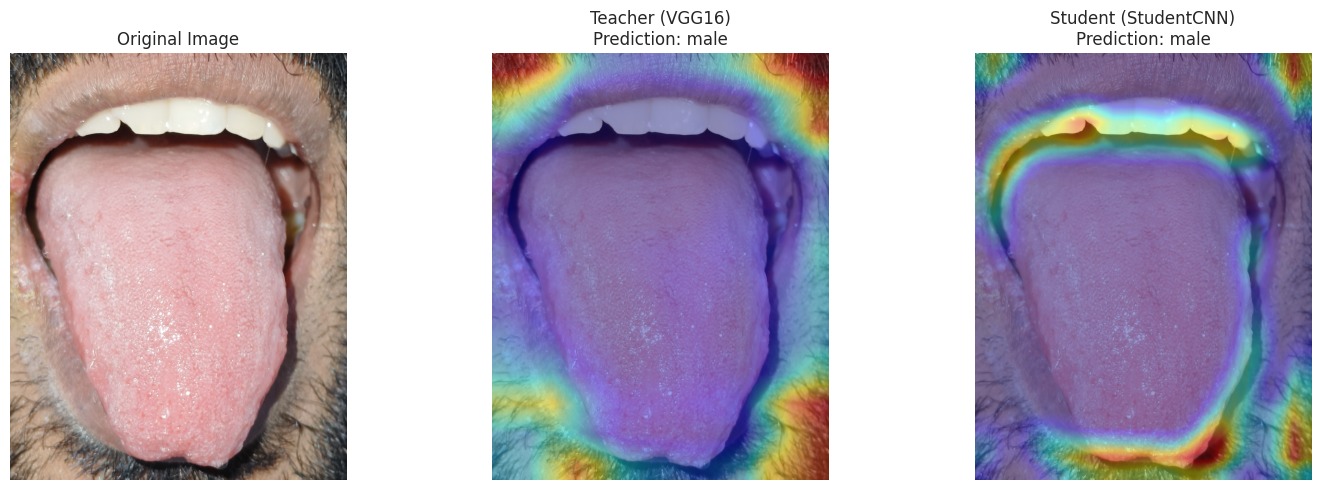

Saved: export/gradcam/gradcam_comparison_5.png
Teacher prediction: male
Student prediction: male
--------------------------------------------------
Grad-CAM comparisons saved in: export/gradcam


In [ ]:

# Grad-CAM Comparison: Teacher (VGG16) vs Student (StudentCNN)

import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn as nn

# 1. Set models to evaluation mode on the same device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
teacher = teacher.to(device).eval()
student = student.to(device).eval()

# 2. Select the last convolutional layer of each model
teacher_layer = [m for m in teacher.features.modules()
                 if isinstance(m, nn.Conv2d)][-1]

if hasattr(student, "conv4") and isinstance(student.conv4, nn.Module):
    student_layer = student.conv4
else:
    student_layer = [m for m in student.modules()
                     if isinstance(m, nn.Conv2d)][-1]

# 3. Grad-CAM function
def make_gradcam(model, layer, image_tensor, forward_fn):
    activations = []
    gradients = []

    def forward_hook(module, inputs, output):
        activations.append(output)
        output.register_hook(lambda grad: gradients.append(grad))

    handle = layer.register_forward_hook(forward_hook)

    try:
        model.zero_grad(set_to_none=True)

        # Do not use torch.no_grad() here; Grad-CAM needs gradients
        logits = forward_fn(image_tensor)
        if isinstance(logits, (tuple, list)):
            logits = logits[0]

        predicted_index = int(logits.argmax(dim=1).item())
        logits[0, predicted_index].backward()

        activation = activations[0].detach()
        gradient = gradients[0].detach()

        weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activation).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam,
            size=image_tensor.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam, predicted_index, logits.detach()

    finally:
        handle.remove()

# 4. Create output folder
output_dir = "export/gradcam"
os.makedirs(output_dir, exist_ok=True)

# 5. Compare up to five test images
num_images = min(5, len(test_df))

for i in range(num_images):
    row = test_df.iloc[i]
    image_path = row["image_path"]

    # Load original image
    pil_img = Image.open(image_path).convert("RGB")
    original = np.array(pil_img)

    # Apply the same Student evaluation transform used in testing
    xs = transform_student_eval(pil_img).unsqueeze(0).to(device)

    # Teacher Grad-CAM: helper must preserve gradients through teacher.features
    teacher_cam, teacher_idx, teacher_logits = make_gradcam(
        teacher,
        teacher_layer,
        xs,
        lambda x: vgg_logits_from_student(x, training=True)
    )

    # Student Grad-CAM
    student_cam, student_idx, student_logits = make_gradcam(
        student,
        student_layer,
        xs,
        lambda x: student(x)
    )

    # Convert CAMs to colored heatmaps
    def overlay_cam(original, cam):
        cam = cv2.resize(cam, (original.shape[1], original.shape[0]))
        heatmap = cv2.applyColorMap(
            np.uint8(255 * cam), cv2.COLORMAP_JET
        )
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        return cv2.addWeighted(original, 0.60, heatmap, 0.40, 0)

    teacher_overlay = overlay_cam(original, teacher_cam)
    student_overlay = overlay_cam(original, student_cam)

    # Class predictions
    teacher_name = CLASS_NAMES[teacher_idx]
    student_name = CLASS_NAMES[student_idx]

    # Display comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(original)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(teacher_overlay)
    axes[1].set_title(f"Teacher (VGG16)\nPrediction: {teacher_name}")
    axes[1].axis("off")

    axes[2].imshow(student_overlay)
    axes[2].set_title(f"Student (StudentCNN)\nPrediction: {student_name}")
    axes[2].axis("off")

    plt.tight_layout()

    save_path = os.path.join(output_dir, f"gradcam_comparison_{i+1}.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")
    print(f"Teacher prediction: {teacher_name}")
    print(f"Student prediction: {student_name}")
    print("-" * 50)

print(f"Grad-CAM comparisons saved in: {output_dir}")


In [ ]:

# STEP 2: Validate exported model on real test images

import torch
import pandas as pd
from PIL import Image
from pathlib import Path

# 1. Load the exported model on CPU
mobile_path = Path("export/student_mobile.ptl")

mobile_model = torch.jit.load(
    str(mobile_path), map_location="cpu"
)
mobile_model.eval()

# 2. Prepare both models
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
student = student.to(device).eval()

results = []

# 3. Test every image in the test dataset
for _, row in test_df.iterrows():

    # Load a real test image
    image = Image.open(row["image_path"]).convert("RGB")

    # Use the same preprocessing as StudentCNN training
    x = transform_student_eval(image).unsqueeze(0)

    # Original StudentCNN prediction
    with torch.no_grad():
        original_output = student(x.to(device))
        original_index = original_output.argmax(dim=1).item()

    # Exported mobile model prediction
    with torch.no_grad():
        mobile_output = mobile_model(x.cpu())
        mobile_index = mobile_output.argmax(dim=1).item()

    original_class = CLASS_NAMES[original_index]
    mobile_class = CLASS_NAMES[mobile_index]

    results.append({
        "Image": Path(row["image_path"]).name,
        "Original Student": original_class,
        "Exported Model": mobile_class,
        "Match": original_index == mobile_index
    })

# 4. Display results
results_df = pd.DataFrame(results)

print("REAL-IMAGE VALIDATION RESULTS")
display(results_df)

# 5. Calculate prediction agreement
if len(results_df) > 0:
    matches = results_df["Match"].sum()
    total = len(results_df)
    agreement = matches / total * 100

    print(f"\nImages tested: {total}")
    print(f"Matching predictions: {matches}/{total}")
    print(f"Prediction agreement: {agreement:.2f}%")

    if matches == total:
        print("SUCCESS: All predictions match.")
    else:
        print("Some predictions differ. Check preprocessing and model export.")
else:
    print("No test images found.")


REAL-IMAGE VALIDATION RESULTS


,Image,Original Student,Exported Model,Match
0,F IMG (9).jpg,female,female,True
1,F IMG (15).JPG,female,female,True
2,F IMG (172).jpg,female,female,True
3,M IMG (130).jpg,female,female,True
4,1000190010.jpg,male,male,True
...,...,...,...,...
94,F IMG (28).JPG,female,female,True
95,F IMG (66).jpg,male,male,True
96,F IMG (276).jpg,female,female,True
97,F IMG (82).jpg,female,female,True



Images tested: 99
Matching predictions: 99/99
Prediction agreement: 100.00%
SUCCESS: All predictions match.


FINAL MODEL COMPARISON


,Metric,Teacher (VGG16),StudentCNN,Exported Student
0,Test Accuracy (%),8.462000e+01,65.38,65.38
1,Parameters,1.266335e+08,800706.00,800706.00
2,Compression Ratio,1.000000e+00,158.15,158.15
3,Parameter Reduction (%),0.000000e+00,99.37,99.37
4,Prediction Agreement (%),NaN,NaN,100.00


Accuracy difference: 19.24 percentage points
Model compression: 158.15x
Parameter reduction: 99.37%
Export prediction agreement: 26/26 (100.00%)


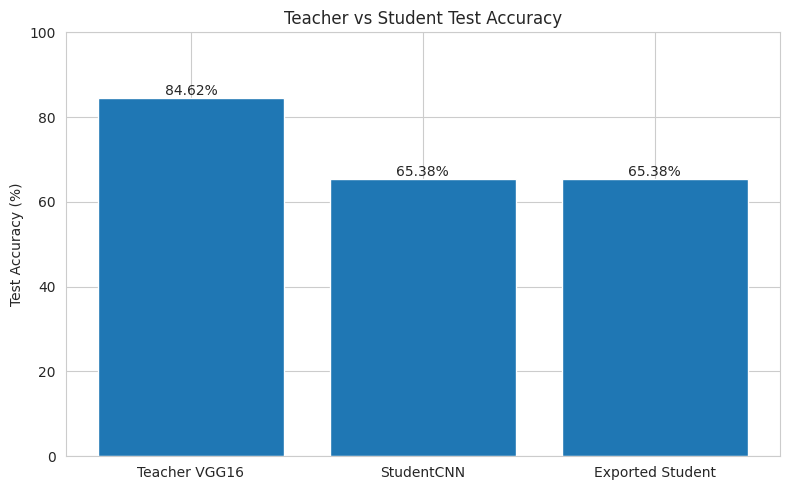

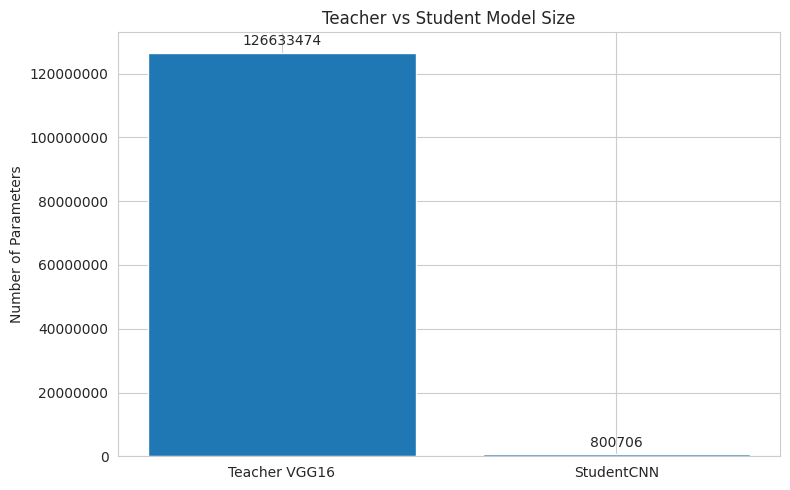

Charts saved:
export/accuracy_comparison.png
export/parameter_comparison.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Create output folder
os.makedirs("export", exist_ok=True)

# Existing project results
teacher_accuracy = 84.62
student_accuracy = 65.38
exported_accuracy = student_accuracy  # Same predictions as StudentCNN

teacher_params = 126_633_474
student_params = 800_706

matching_images = 26
total_images = 26

# Calculate metrics
compression_ratio = teacher_params / student_params
parameter_reduction = (
    (teacher_params - student_params) / teacher_params
) * 100
accuracy_difference = teacher_accuracy - student_accuracy
agreement = matching_images / total_images * 100

# 1. Final results table
results = pd.DataFrame({
    "Metric": [
        "Test Accuracy (%)",
        "Parameters",
        "Compression Ratio",
        "Parameter Reduction (%)",
        "Prediction Agreement (%)"
    ],
    "Teacher (VGG16)": [
        teacher_accuracy,
        teacher_params,
        1.0,
        0.0,
        None
    ],
    "StudentCNN": [
        student_accuracy,
        student_params,
        round(compression_ratio, 2),
        round(parameter_reduction, 2),
        None
    ],
    "Exported Student": [
        exported_accuracy,
        student_params,
        round(compression_ratio, 2),
        round(parameter_reduction, 2),
        agreement
    ]
})

print("FINAL MODEL COMPARISON")
display(results)

print(f"Accuracy difference: {accuracy_difference:.2f} percentage points")
print(f"Model compression: {compression_ratio:.2f}x")
print(f"Parameter reduction: {parameter_reduction:.2f}%")
print(f"Export prediction agreement: {matching_images}/{total_images} ({agreement:.2f}%)")

# 2. Accuracy comparison chart
models = ["Teacher VGG16", "StudentCNN", "Exported Student"]
accuracies = [
    teacher_accuracy,
    student_accuracy,
    exported_accuracy
]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)
plt.ylabel("Test Accuracy (%)")
plt.title("Teacher vs Student Test Accuracy")
plt.ylim(0, 100)
plt.bar_label(bars, fmt="%.2f%%")
plt.tight_layout()
plt.savefig("export/accuracy_comparison.png", dpi=200)
plt.show()

# 3. Parameter count comparison chart
parameter_counts = [teacher_params, student_params]

plt.figure(figsize=(8, 5))
bars = plt.bar(
    ["Teacher VGG16", "StudentCNN"],
    parameter_counts
)
plt.ylabel("Number of Parameters")
plt.title("Teacher vs Student Model Size")
plt.ticklabel_format(axis="y", style="plain")
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.tight_layout()
plt.savefig("export/parameter_comparison.png", dpi=200)
plt.show()

print("Charts saved:")
print("export/accuracy_comparison.png")
print("export/parameter_comparison.png")


In [ ]:

from sklearn.metrics import accuracy_score, classification_report

# Get actual labels from your test dataframe.
# This assumes test_df["label"] contains the true class names.
y_true = test_df["label"].tolist()

# If your dataframe labels are strings such as "female"/"male":
y_true = [str(label).lower() for label in y_true]

# Collect predictions from the original Student model
y_pred = []

student.eval()

for _, row in test_df.iterrows():
    from PIL import Image

    image = Image.open(row["image_path"]).convert("RGB")
    x = transform_student_eval(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = student(x)

    predicted_index = output.argmax(dim=1).item()
    y_pred.append(str(CLASS_NAMES[predicted_index]).lower())

print("StudentCNN accuracy:",
      round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(y_true, y_pred, zero_division=0))


StudentCNN accuracy: 63.64 %

Classification report:
              precision    recall  f1-score   support

      female       0.62      0.83      0.71        53
        male       0.68      0.41      0.51        46

    accuracy                           0.64        99
   macro avg       0.65      0.62      0.61        99
weighted avg       0.65      0.64      0.62        99



In [ ]:
import torch.nn as nn

def show_activations(model, model_name):
    print(f"\n{model_name} activation modules:")

    found = False

    for name, layer in model.named_modules():
        if isinstance(layer, (
            nn.ReLU,
            nn.LeakyReLU,
            nn.GELU,
            nn.Sigmoid,
            nn.Tanh,
            nn.Softmax,
            nn.LogSoftmax
        )):
            print(f"{name}: {layer}")
            found = True

    if not found:
        print("No listed activation modules found.")

show_activations(teacher, "Teacher (VGG16)")
show_activations(student, "StudentCNN")


Teacher (VGG16) activation modules:
features.1: ReLU(inplace=True)
features.3: ReLU(inplace=True)
features.6: ReLU(inplace=True)
features.8: ReLU(inplace=True)
features.11: ReLU(inplace=True)
features.13: ReLU(inplace=True)
features.15: ReLU(inplace=True)
features.18: ReLU(inplace=True)
features.20: ReLU(inplace=True)
features.22: ReLU(inplace=True)
features.25: ReLU(inplace=True)
features.27: ReLU(inplace=True)
features.29: ReLU(inplace=True)
classifier.1: ReLU(inplace=True)
classifier.4: ReLU(inplace=True)

StudentCNN activation modules:
relu: ReLU()


Using device: cuda
Classes: ['female', 'male']

VGG16 Teacher Evaluation
Accuracy  : 0.8283 (82.83%)
Precision : 0.8320
Recall    : 0.8238
F1-score  : 0.8257

Classification Report:
              precision    recall  f1-score   support

      female     0.8103    0.8868    0.8468        53
        male     0.8537    0.7609    0.8046        46

    accuracy                         0.8283        99
   macro avg     0.8320    0.8238    0.8257        99
weighted avg     0.8305    0.8283    0.8272        99



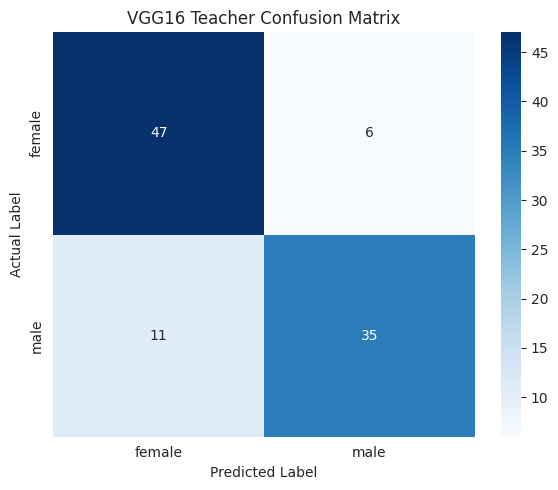


StudentCNN Evaluation
Accuracy  : 0.6364 (63.64%)
Precision : 0.6491
Recall    : 0.6216
F1-score  : 0.6116

Classification Report:
              precision    recall  f1-score   support

      female     0.6197    0.8302    0.7097        53
        male     0.6786    0.4130    0.5135        46

    accuracy                         0.6364        99
   macro avg     0.6491    0.6216    0.6116        99
weighted avg     0.6471    0.6364    0.6185        99



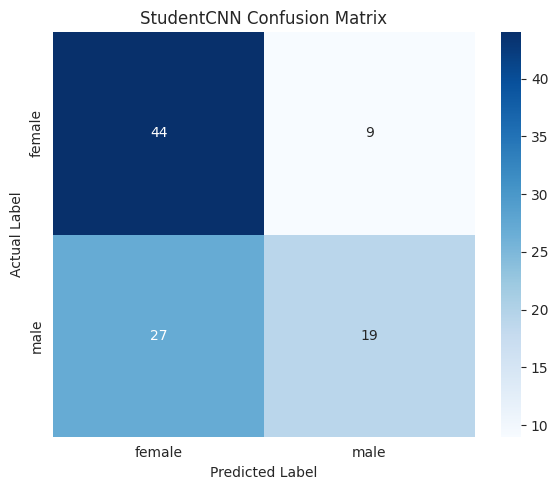


FINAL MODEL COMPARISON
        Model  Accuracy (%)  Precision (Macro)  Recall (Macro)  F1-score (Macro)
VGG16 Teacher       82.8283             0.8320          0.8238            0.8257
   StudentCNN       63.6364             0.6491          0.6216            0.6116


In [ ]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 2. Class names
class_names = list(CLASS_NAMES)
print("Classes:", class_names)

# 3. Evaluation transforms
# Use the SAME preprocessing used during training for each model.

teacher_transform = transforms.Compose([
    transforms.Resize(tuple(IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Reuse your existing student evaluation transform
student_transform = transform_student_eval


# 4. Test dataset
class EvaluationDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)

        label = row["label"]

        if isinstance(label, str):
            label = class_names.index(label)

        return image, int(label)


teacher_loader = DataLoader(
    EvaluationDataset(test_df, teacher_transform),
    batch_size=16,
    shuffle=False
)

student_loader = DataLoader(
    EvaluationDataset(test_df, student_transform),
    batch_size=16,
    shuffle=False
)


# 5. Calculate evaluation metrics
def evaluate_model(model, loader, model_name):
    model = model.to(device)
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    print(f"\n{'=' * 45}")
    print(f"{model_name} Evaluation")
    print(f"{'=' * 45}")
    print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names)))
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-score (Macro)": f1
    }


# 6. Evaluate both trained models
teacher_results = evaluate_model(
    teacher, teacher_loader, "VGG16 Teacher"
)

student_results = evaluate_model(
    student, student_loader, "StudentCNN"
)


# 7. Compare both models
comparison = pd.DataFrame([
    teacher_results,
    student_results
])

print("\nFINAL MODEL COMPARISON")
print(comparison.round(4).to_string(index=False))
